In [4]:
#set working directory to project root
from pathlib import Path
import sys

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

print(project_root)

project_dir = Path("/Users/henristaehelin/Desktop/UZH/SDS320/project")

if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

images_dir = project_dir / "data/raw/imagery/sentinel2"
masks_dir = project_dir / "data/raw/raster"

print("Project:", project_dir)
print("Images exist:", images_dir.exists())
print("Masks exist:", masks_dir.exists())

/Users/henristaehelin/Desktop/UZH/SDS320/project
Project: /Users/henristaehelin/Desktop/UZH/SDS320/project
Images exist: True
Masks exist: True


# 1. Load Crop Data, Choose Areas
We load data of crop field polygons and class types from Germany in 2023. In addition we choose scenes in which we will train, validate and test the model. 

#### a) Load Germany 2023 Data from the Eurocrops Dataset
Using the function "load_crop_fields" saved in a separate R script. It uses country code identifiers "nuts" to choose germany "dea", and ensures original names match the international crop label "hcat4_name".

In [5]:
from scripts.crop_field_loading import load_crop_fields

germany_2023 = load_crop_fields(
    vector_path=project_dir / "data/raw/vectors/dea_2023.parquet",
    lookup_path=project_dir / "data/raw/Eurocrops.csv",
    country_code="dea",
)

display(germany_2023.head())

,cropfield,original_code,off_id,off_area,area_ha,geometry,nuts,original_name,translated_name,hcat4_code,hcat4_name,usage_code,usage_name
0,713879,575,7158611,0.1413,0.141340,"MULTIPOLYGON (((4075066.904 3118777.11, 407491...",dea,Blühfläche (AUM-Altmaßnahme,Flowering area (AUM-old measure),3310800000,flowers_ornamental_plants,0,No specified use
1,709592,66,7103747,0.0777,0.077780,"MULTIPOLYGON (((4061747.758 3135219.228, 40615...",dea,Kond.-Brache (aktive Begrünun,Fallow land (active greening),3311100000,fallow_land_not_crop,0,No specified use
2,711311,994,7060421,0.0053,0.005314,"MULTIPOLYGON (((4242608.123 3250820.547, 42426...",dea,Unbefestigte Mieten DGL,Unfixed rents permanent grass land,3320100000,permanent_grassland,0,No specified use
3,713404,996,7131892,0.0639,0.064025,"MULTIPOLYGON (((4229259.343 3207621.8, 4229293...",dea,Unbefestigte Mieten AL,unfixed rents AL,3390000000,not_known_and_other,0,No specified use
4,713622,860,7135902,2.8559,2.857417,"MULTIPOLYGON (((4142676.982 3210526.616, 41427...",dea,Spargel,asparagus,3310706000,asparagus,0,No specified use


We now have polygons and labels. We will use hcat4_name as this is the harmonized label across multiple countries.

Lets also see how many unique crops there are. 

In [6]:
#see number of unique crops
print(germany_2023["hcat4_name"].nunique())
print(germany_2023["hcat4_code"].nunique()) #making sure number of unique names and codes line up

173
173


#### b) Choose subset of crop types and set crop ids
Instead lets choose the 30 most common crop types. Upon inspection of the crop types there are some which might be unsuitable for a model because they are ambiguous/miscellaneous and have no clear type or consistent spectral info which the model could learn. 

In [7]:
# Exclude unsuitable or ambiguous crop categories
excluded_crops = [
    "fallow_land_not_crop",
    "not_known_and_other",
    "unmaintained",
    "seed_seedlings",
    "nurseries_nursery",
    "poaceae_grasses",
    "other_flowers_ornamental_plants",
    "flowers_ornamental_plants",
    "other_aromatic_medicinal_culinary_plants_spices_herbs",
    "afforestation_reforestation",
    "spring_mixed_grains",
    "other_industrial_crops",
    "other_poaceae_grasses",
    "other_arable_land_crops",
]

crop_counts = (
    germany_2023.loc[
        ~germany_2023["hcat4_name"].isin(excluded_crops),
        "hcat4_name"
    ]
    .value_counts()
)

subset = crop_counts.head(30).index.tolist()

display(crop_counts.head(30))

hcat4_name
permanent_grassland         294894
maize_corn_popcorn           91195
winter_common_soft_wheat     69959
winter_barley                43410
temporary_grassland          28327
winter_triticale             17376
winter_rapeseed_rape         16689
winter_rye                   15277
sugar_beet                   13079
potatoes                     11308
orchards_fruits               9073
clover                        5298
spring_barley                 3529
spring_oats                   3289
beans                         3072
peas                          2117
asparagus                     1672
alfalfa_lucerne               1506
strawberries                  1452
spring_common_soft_wheat      1320
cereal                        1171
fresh_vegetables              1011
onions                         915
pumpkin_squash_gourd           903
conifers                       903
brassicaceae_cruciferae        881
carrots_daucus                 868
winter_spelt                   808
miscanthu

In [8]:
# Keep only the 30 selected crop types
reduced_crops = germany_2023[
    germany_2023["hcat4_name"].isin(subset)
].copy()

print("Original polygons:", len(germany_2023))
print("Subset polygons:", len(reduced_crops))
print("% Polygons kept:", round(len(reduced_crops)/(len(germany_2023))*100))
print("Crop types present:", reduced_crops["hcat4_name"].nunique())

reduced_crops.head(5)

Original polygons: 748208
Subset polygons: 642867
% Polygons kept: 86
Crop types present: 30


,cropfield,original_code,off_id,off_area,area_ha,geometry,nuts,original_name,translated_name,hcat4_code,hcat4_name,usage_code,usage_name
2,711311,994,7060421,0.0053,0.005314,"MULTIPOLYGON (((4242608.123 3250820.547, 42426...",dea,Unbefestigte Mieten DGL,Unfixed rents permanent grass land,3320100000,permanent_grassland,0,No specified use
4,713622,860,7135902,2.8559,2.857417,"MULTIPOLYGON (((4142676.982 3210526.616, 41427...",dea,Spargel,asparagus,3310706000,asparagus,0,No specified use
6,714367,602,7209215,0.6296,0.629910,"MULTIPOLYGON (((4115046.183 3117774.226, 41151...",dea,Kartoffeln,potatoes,3310300000,potatoes,0,No specified use
9,716260,115,7061460,2.4301,2.432082,"MULTIPOLYGON (((4243063.131 3249725.238, 42432...",dea,Winterweichweizen,Winter soft wheat,3310101001,winter_common_soft_wheat,0,No specified use
10,716676,633,7282261,0.1645,0.164611,"MULTIPOLYGON (((4085257.054 3150768.223, 40852...",dea,Zwiebeln/Lauch,Onions / leeks,3310708040,onions,0,No specified use


In [9]:
# Define consistent crop IDs before selecting areas
crop_mapping = {
    name: i + 1
    for i, name in enumerate(
        sorted(reduced_crops["hcat4_name"].dropna().unique())
    )
}

assert len(crop_mapping) == 30
print(crop_mapping)

{'alfalfa_lucerne': 1, 'asparagus': 2, 'beans': 3, 'berries_berry_species': 4, 'brassicaceae_cruciferae': 5, 'carrots_daucus': 6, 'cereal': 7, 'clover': 8, 'conifers': 9, 'fresh_vegetables': 10, 'maize_corn_popcorn': 11, 'miscanthus_silvergrass': 12, 'onions': 13, 'orchards_fruits': 14, 'peas': 15, 'permanent_grassland': 16, 'potatoes': 17, 'pumpkin_squash_gourd': 18, 'spring_barley': 19, 'spring_common_soft_wheat': 20, 'spring_oats': 21, 'strawberries': 22, 'sugar_beet': 23, 'temporary_grassland': 24, 'winter_barley': 25, 'winter_common_soft_wheat': 26, 'winter_rapeseed_rape': 27, 'winter_rye': 28, 'winter_spelt': 29, 'winter_triticale': 30}


#### c) Choose Areas and define the split.
We will choose areas for where our model will train, validate and test, in a 70/15/15 split. Ideally we choose areas that have an even spread of crop types present and all 30 crop types we selected are represented. 

Lets choose 50 of them, and set a 10km minimum distance between area boundaries to avoid areas being too similar. Also lets prioritize rare crop types and ensure that there is an even crop spread and all 30 crop types are represented. We have a candidate score which is based on crop distribution within the areas, with higher numbers being more diverse. The code below runs on functions in a python script. This allows us to easily change the number of areas and area size in (m^2)

Selected areas: 50


,area_id,grid_id,n_crop_types,n_fields,score,geometry
0,1,729,28,660,48.122110,"POLYGON ((358400 5621760, 358400 5626880, 3532..."
1,2,822,25,838,21.527579,"POLYGON ((368640 5606400, 368640 5611520, 3635..."
2,3,261,22,596,15.915255,"POLYGON ((307200 5683200, 307200 5688320, 3020..."
3,4,498,23,575,12.091104,"POLYGON ((332800 5667840, 332800 5672960, 3276..."
4,5,2043,21,783,10.410864,"POLYGON ((496640 5713920, 496640 5719040, 4915..."


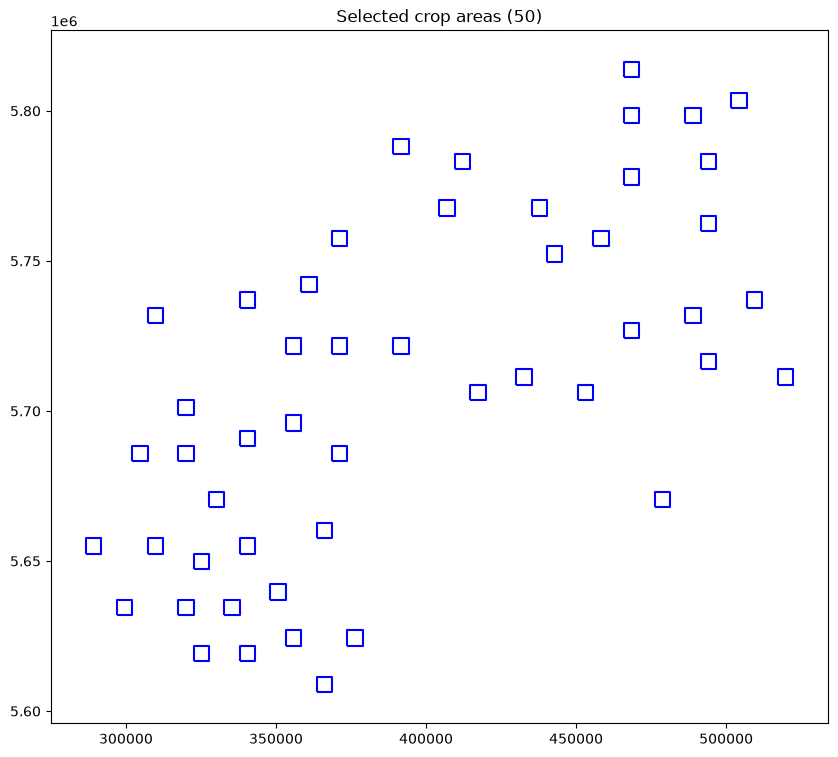

In [10]:
from scripts.crop_area_selection import select_crop_areas, plot_crop_areas
import matplotlib.pyplot as plt

selected_areas = select_crop_areas(
    crop_fields=reduced_crops,
    area_size=5120, #this number is useful for creating strides later
    n_areas=50,
    min_distance=10000,
    min_crop_types=10,
)

print(f"Selected areas: {len(selected_areas)}")

display(selected_areas.head())

fig, ax = plot_crop_areas(selected_areas)
plt.show()

Finally we split the selected areas into train, validation and test areas using a 70/15/15 split. 

In [11]:
import numpy as np

# Reproducible random split of geographic areas
rng = np.random.default_rng(42)

area_ids = rng.permutation(selected_areas["area_id"].to_numpy())

n_train = round(len(area_ids) * 0.70)
n_val = round(len(area_ids) * 0.15)

split_by_area = {
    int(area_id): (
        "train" if i < n_train
        else "val" if i < n_train + n_val
        else "test"
    )
    for i, area_id in enumerate(area_ids)
}

# Add split assignments to the GeoDataFrame
selected_areas["split"] = selected_areas["area_id"].map(split_by_area)

print(selected_areas["split"].value_counts())

split
train    35
val       8
test      7
Name: count, dtype: int64


# 2. Choose/Load Sentinel-2 Data Scenes, Overlay Crop Polygons on to Raster

When choosing scenes, ideally they have low cloud cover so that the spectral reflectance of the crop is what the model learns. Also then the OmniCloudMask has to do less work and we have better images. 

#### Insert script and function explanation here:

In [12]:
from scripts.sentinel2_monthly_composites import create_monthly_composites

# First, test on one area
results = create_monthly_composites(
    selected_areas=selected_areas,
    output_dir=project_dir / "data/processed/sentinel2_monthly_2023",
    year=2023,
    months=range(3, 11),
    scenes_per_month=5,
    max_cloud_cover=60,
    pixel_size=10,
    inference_device="mps",
)


Area 1: reusing completed stack
Area 2: reusing completed stack
Area 3: reusing completed stack
Area 4: reusing completed stack
Area 5: reusing completed stack
Area 6: reusing completed stack
Area 7: reusing completed stack
Area 8: reusing completed stack
Area 9: reusing completed stack
Area 10: reusing completed stack
Area 11: reusing completed stack
Area 12: reusing completed stack
Area 13: reusing completed stack
Area 14: reusing completed stack
Area 15: reusing completed stack
Area 16: reusing completed stack
Area 17: reusing completed stack
Area 18: reusing completed stack
Area 19: reusing completed stack
Area 20: reusing completed stack
Area 21: reusing completed stack
Area 22: reusing completed stack
Area 23: reusing completed stack
Area 24: reusing completed stack
Area 25: reusing completed stack
Area 26: reusing completed stack
Area 27: reusing completed stack
Area 28: reusing completed stack
Area 29: reusing completed stack
Area 30: reusing completed stack
Area 31: reusing co

Create monthly composites that are only from the 8th to the 24th of the month to avoid March 31st to April 1st issues. 

Output directory: project_dir / "data/processed/sentinel2_monthly_2023_8to24"

In [13]:
from scripts.sentinel2_monthly_composites_8to24 import create_monthly_composites

results = create_monthly_composites(
    selected_areas=selected_areas,
    output_dir=project_dir / "data/processed/sentinel2_monthly_2023_8to24",
    year=2023,
    months=range(3, 11),
    scenes_per_month=5,
    max_cloud_cover=60,
    start_day=8,
    end_day=24,
    pixel_size=10,
    inference_device="mps",
)

display(results)

Area 1: reusing completed stack
Area 2: reusing completed stack
Area 3: reusing completed stack
Area 4: reusing completed stack
Area 5: reusing completed stack
Area 6: reusing completed stack
Area 7: reusing completed stack
Area 8: reusing completed stack
Area 9: reusing completed stack
Area 10: reusing completed stack
Area 11: reusing completed stack
Area 12: reusing completed stack
Area 13: reusing completed stack
Area 14: reusing completed stack
Area 15: reusing completed stack
Area 16: reusing completed stack
Area 17: reusing completed stack
Area 18: reusing completed stack
Area 19: reusing completed stack
Area 20: reusing completed stack
Area 21: reusing completed stack
Area 22: reusing completed stack
Area 23: reusing completed stack
Area 24: reusing completed stack
Area 25: reusing completed stack
Area 26: reusing completed stack
Area 27: reusing completed stack
Area 28: reusing completed stack
Area 29: reusing completed stack
Area 30: reusing completed stack
Area 31: reusing co

/Users/henristaehelin/miniconda3/envs/sds320-geoai-test/lib/python3.12/site-packages/omnicloudmask/cloud_mask.py:456: UserWarning: Patch size too large, reducing to 512 and overlap to 256.
  patch_overlap, patch_size = check_patch_size(


Area 39, 2023-03: 1/1 scenes, 0.4% pixels with clear observation
Area 39, 2023-04: 0/0 scenes, 0.0% pixels with clear observation


/Users/henristaehelin/miniconda3/envs/sds320-geoai-test/lib/python3.12/site-packages/omnicloudmask/cloud_mask.py:456: UserWarning: Patch size too large, reducing to 512 and overlap to 256.
  patch_overlap, patch_size = check_patch_size(


Area 39, 2023-05: 1/1 scenes, 21.6% pixels with clear observation


/Users/henristaehelin/miniconda3/envs/sds320-geoai-test/lib/python3.12/site-packages/omnicloudmask/cloud_mask.py:456: UserWarning: Patch size too large, reducing to 512 and overlap to 256.
  patch_overlap, patch_size = check_patch_size(


... (10 outputs left out)

Area 40, 2023-03: 2/2 scenes, 82.2% pixels with clear observation


/Users/henristaehelin/miniconda3/envs/sds320-geoai-test/lib/python3.12/site-packages/omnicloudmask/cloud_mask.py:456: UserWarning: Patch size too large, reducing to 512 and overlap to 256.
  patch_overlap, patch_size = check_patch_size(


Area 40, 2023-04: 1/1 scenes, 60.5% pixels with clear observation


KeyboardInterrupt: 

In [14]:
import rasterio

area_id = int(selected_areas.iloc[0]["area_id"])

path = (
    project_dir
    / "data/processed/sentinel2_monthly_2023/images"
    / f"germany_2023_area_{area_id}.tif"
)

with rasterio.open(path) as src:
    print("Bands:", src.count)
    print("Dimensions:", src.width, "×", src.height)
    print("CRS:", src.crs)
    print("Band descriptions:", src.descriptions)

Bands: 80
Dimensions: 512 × 512
CRS: EPSG:32632
Band descriptions: ('2023-03_B02', '2023-03_B03', '2023-03_B04', '2023-03_B08', '2023-03_B05', '2023-03_B06', '2023-03_B07', '2023-03_B8A', '2023-03_B11', '2023-03_B12', '2023-04_B02', '2023-04_B03', '2023-04_B04', '2023-04_B08', '2023-04_B05', '2023-04_B06', '2023-04_B07', '2023-04_B8A', '2023-04_B11', '2023-04_B12', '2023-05_B02', '2023-05_B03', '2023-05_B04', '2023-05_B08', '2023-05_B05', '2023-05_B06', '2023-05_B07', '2023-05_B8A', '2023-05_B11', '2023-05_B12', '2023-06_B02', '2023-06_B03', '2023-06_B04', '2023-06_B08', '2023-06_B05', '2023-06_B06', '2023-06_B07', '2023-06_B8A', '2023-06_B11', '2023-06_B12', '2023-07_B02', '2023-07_B03', '2023-07_B04', '2023-07_B08', '2023-07_B05', '2023-07_B06', '2023-07_B07', '2023-07_B8A', '2023-07_B11', '2023-07_B12', '2023-08_B02', '2023-08_B03', '2023-08_B04', '2023-08_B08', '2023-08_B05', '2023-08_B06', '2023-08_B07', '2023-08_B8A', '2023-08_B11', '2023-08_B12', '2023-09_B02', '2023-09_B03', '2

In [15]:
import rasterio
import numpy as np
import pandas as pd

area_id = int(selected_areas.iloc[17]["area_id"])

path = (
    project_dir
    / "data/processed/sentinel2_monthly_2023/clear_counts"
    / f"germany_2023_area_{area_id}_clear_counts.tif"
)

months = ["March", "April", "May", "June",
          "July", "August", "September", "October"]

records = []

with rasterio.open(path) as src:
    for i, month in enumerate(months, start=1):
        counts = src.read(i)

        records.append({
            "Month": month,
            "Coverage (%)": round(100 * np.mean(counts > 0), 2),
            "Mean clear observations": round(float(counts.mean()), 2),
            "Pixels with no clear data (%)": round(
                100 * np.mean(counts == 0), 2
            ),
        })

coverage_df = pd.DataFrame(records)
display(coverage_df)

,Month,Coverage (%),Mean clear observations,Pixels with no clear data (%)
0,March,95.20,0.95,4.80
1,April,0.00,0.00,100.00
2,May,100.00,2.24,0.00
3,June,100.00,4.15,0.00
4,July,80.69,1.18,19.31
5,August,97.59,1.37,2.41
6,September,100.00,2.65,0.00
7,October,22.79,0.23,77.21


Overlay the crop polygons onto the composites so that we can have an idea of what the data looks like and ensure that the bounds of the vector and raster are aligned. 

In [16]:
import leafmap
import rasterio
import geopandas as gpd

maps = {}

# Choose which month to display (1 = March, 8 = October)
month = 4  # June

for area_id in [1, 2, 3]:

    # Path to the 80-band composite
    raster_path = (
    project_dir
    / "data/processed/sentinel2_monthly_2023/images"
    / f"germany_2023_area_{area_id}.tif"
)

    if not raster_path.exists():
        print(f"Area {area_id}: composite not found, skipping")
        continue

    # Get crop fields within the selected area
    area = selected_areas.loc[
        selected_areas["area_id"] == area_id
    ].to_crs(reduced_crops.crs)

    crop_fields = gpd.clip(reduced_crops, area)

    # Each month contains 10 bands
    offset = (month - 1) * 10

    m = leafmap.Map(height="500px")
    m.add_basemap("Esri.WorldImagery")

    # True colour: B04, B03, B02
    m.add_raster(
        str(raster_path),
        indexes=[offset + 3, offset + 2, offset + 1],
        layer_name="Sentinel-2 True Color",
    )

    # False colour: B08, B04, B03
    m.add_raster(
        str(raster_path),
        indexes=[offset + 4, offset + 3, offset + 2],
        layer_name="Sentinel-2 False Color",
    )

    m.add_gdf(
        crop_fields,
        layer_name="German Crop Fields",
    )

    m.add_layer_control()

    maps[area_id] = m

    print(f"Map for area {area_id}")
    display(m)

Map for area 1


Map(center=[50.752729, 6.956288000000001], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in…

Map for area 2


Map(center=[50.6171255, 7.106933], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title',…

Map for area 3


Map(center=[51.289604499999996, 6.198150500000001], controls=(ZoomControl(options=['position', 'zoom_in_text',…

# 2b. Temporal Interpolation Preprocessing

In [17]:
from scripts.interpolate_monthly_composites import interpolate_monthly_composites
import pandas as pd

results = interpolate_monthly_composites(
    composites_dir=project_dir / "data/processed/sentinel2_monthly_2023/images",
    clear_counts_dir=project_dir / "data/processed/sentinel2_monthly_2023/clear_counts",
    output_dir=project_dir / "data/processed/sentinel2_monthly_interpolated",
)

germany_2023_area_1: outputs already exist; skipping
germany_2023_area_10: outputs already exist; skipping
germany_2023_area_11: outputs already exist; skipping
germany_2023_area_12: outputs already exist; skipping
germany_2023_area_13: outputs already exist; skipping
germany_2023_area_14: outputs already exist; skipping
germany_2023_area_15: outputs already exist; skipping
germany_2023_area_16: outputs already exist; skipping
germany_2023_area_17: outputs already exist; skipping
germany_2023_area_18: outputs already exist; skipping
germany_2023_area_19: outputs already exist; skipping
germany_2023_area_2: outputs already exist; skipping
germany_2023_area_20: outputs already exist; skipping
germany_2023_area_21: outputs already exist; skipping
germany_2023_area_22: outputs already exist; skipping
germany_2023_area_23: outputs already exist; skipping
germany_2023_area_24: outputs already exist; skipping
germany_2023_area_25: outputs already exist; skipping
germany_2023_area_26: outputs 

# 3. Post Processing and Vectors to Masks
Here we ensure that the crs and bounds of the raster and vector for each area are the same, ensure that there are 80 bands per image. Fields that are intersected by the raster boundary are kept, only the part that is still within the raster. Pixels that are found on field boundaries, so in between two fields are removed and set to ignore (255). 

The script below is contains a function that checks the crs, the bounds and that they are correct for raster and vector. Then it creates masks from the vectors according to the specifications discussed above. 

In [18]:
from scripts.crop_mask_postprocessing import create_checked_crop_masks

summary = create_checked_crop_masks(
    selected_areas=selected_areas,
    crop_fields=reduced_crops,
    crop_mapping=crop_mapping,
    images_dir=project_dir / "data/processed/sentinel2_monthly_2023/images",
    masks_dir=project_dir / "data/processed/masks_80band",
    boundary_buffer_m=5.0,
    expected_bands=80,
)

summary.head(5)

,area_id,crs,bounds_match,raster_shape,fields_intersecting,overlap_pixels,boundary_pixels,labeled_pixels,labeled_percent
0,1,EPSG:32632,True,512x512,731,0,26052,71899,27.43
1,2,EPSG:32632,True,512x512,940,0,33945,112329,42.85
2,3,EPSG:32632,True,512x512,669,0,27901,99769,38.06
3,4,EPSG:32632,True,512x512,668,0,30489,153095,58.40
4,5,EPSG:32632,True,512x512,870,0,35796,129804,49.52


# 4. Tiling into Chips

Step 1: Set paths and verify data sources. Ensures the different geographic areas are split into train/val/test in a 70/15/15 split. 

In [19]:
from pathlib import Path
import numpy as np
import pandas as pd
import rasterio

images_dir = project_dir / "data/processed/sentinel2_monthly_interpolated/images"

masks_dir = (
    project_dir / "data/processed/masks_80band"
)

batch_dir = project_dir / "data/processed/batch_80band"
tiles_dir = project_dir / "data/processed/tiles_80band"

n_classes = len(crop_mapping)
allowed_ids = set(crop_mapping.values()) | {255}

assert set(crop_mapping.values()) == set(range(1, n_classes + 1))
assert selected_areas["area_id"].is_unique

area_ids = selected_areas["area_id"].astype(int).tolist()

assert set(area_ids) == set(split_by_area)
assert set(split_by_area.values()) == {"train", "val", "test"}

source_pairs = []
records = []

for area_id in area_ids:
    image_path = images_dir / f"germany_2023_area_{area_id}.tif"
    mask_path = masks_dir / f"germany_mask_{area_id}.tif"

    if not image_path.exists():
        raise FileNotFoundError(image_path)
    if not mask_path.exists():
        raise FileNotFoundError(mask_path)

    with rasterio.open(image_path) as image, \
         rasterio.open(mask_path) as mask:

        assert image.count == 80, f"Area {area_id}: expected 80 bands"
        assert mask.count == 1
        assert image.crs == mask.crs
        assert image.transform == mask.transform
        assert image.width == mask.width
        assert image.height == mask.height
        assert image.crs.is_projected
        assert np.isclose(abs(image.res[0]), 10)
        assert np.isclose(abs(image.res[1]), 10)

        labels = mask.read(1)
        invalid = set(map(int, np.unique(labels))) - allowed_ids
        assert not invalid, f"Area {area_id}: invalid IDs {invalid}"
        assert np.any(labels != 255), f"Area {area_id}: no crop labels"

        records.append({
            "area_id": area_id,
            "split": split_by_area[area_id],
            "bands": image.count,
            "width": image.width,
            "height": image.height,
            "crs": str(image.crs),
            "labeled_pct": round(100 * np.mean(labels != 255), 2),
        })

    source_pairs.append((area_id, image_path, mask_path))

source_summary = pd.DataFrame(records)

print("Geographic area split:")
print(source_summary["split"].value_counts())

print("\nSource validation:")
display(source_summary)

assert len(source_pairs) == len(area_ids)

print("All source image-mask pairs validated.")

Geographic area split:
split
train    35
val       8
test      7
Name: count, dtype: int64

Source validation:


,area_id,split,bands,width,height,crs,labeled_pct
0,1,val,80,512,512,EPSG:32632,27.43
1,2,test,80,512,512,EPSG:32632,42.85
2,3,test,80,512,512,EPSG:32632,38.06
3,4,train,80,512,512,EPSG:32632,58.40
4,5,train,80,512,512,EPSG:32632,49.52
5,6,train,80,512,512,EPSG:32632,52.23
6,7,val,80,512,512,EPSG:32632,56.58
7,8,train,80,512,512,EPSG:32632,50.91
8,9,test,80,512,512,EPSG:32632,62.39
9,10,train,80,512,512,EPSG:32632,54.98


All source image-mask pairs validated.


Step 2: GeoAI will remap the crop ids which we don't want to happen so we apply a patch to the function. It keeps the crop ids labeled 1-30 and also the unlabeled areas as 255 (ignore). 

In [20]:
import geoai
import inspect
import rasterio
import numpy as np
from rasterio.windows import from_bounds

training = inspect.getmodule(geoai.export_geotiff_tiles_batch)

ALLOWED_LABEL_VALUES = set(range(1, n_classes + 1)) | {255}

def load_raster_labels_preserving_ids(
    class_raster_path,
    src_crs,
    quiet=False,
    metadata_format=None,
):
    with rasterio.open(class_raster_path) as src:
        if src.crs != src_crs:
            raise ValueError("Image and mask CRS do not match")

        values = set(map(int, np.unique(src.read(1))))

        if not values <= ALLOWED_LABEL_VALUES | {0}:
            raise ValueError(f"Unexpected crop IDs: {values}")

    return {i: i for i in range(1, n_classes + 1)}, []


def read_label_tile_preserving_ids(
    class_raster_path,
    minx,
    miny,
    maxx,
    maxy,
    tile_size,
    class_to_id,
):
    with rasterio.open(class_raster_path) as src:

        bounds = src.bounds

        if (
            minx >= bounds.right
            or maxx <= bounds.left
            or miny >= bounds.top
            or maxy <= bounds.bottom
        ):
            return (
                np.full((tile_size, tile_size), 255, dtype=np.uint8),
                False,
            )

        window = from_bounds(
            minx, miny, maxx, maxy,
            transform=src.transform,
        )

        data = src.read(
            1,
            window=window,
            boundless=True,
            out_shape=(tile_size, tile_size),
            fill_value=255,
            resampling=rasterio.enums.Resampling.nearest,
        ).astype(np.uint8)

    data[data == 0] = 255

    values = set(map(int, np.unique(data)))

    if not values <= ALLOWED_LABEL_VALUES:
        raise ValueError(f"Unexpected crop IDs in tile: {values}")

    has_crops = bool(np.any(data != 255))

    return data, has_crops


# Patch GeoAI's internal tiling functions
training._load_class_data_raster = load_raster_labels_preserving_ids
training._rasterize_label_from_raster = read_label_tile_preserving_ids

assert (
    training._load_class_data_raster
    is load_raster_labels_preserving_ids
)

assert (
    training._rasterize_label_from_raster
    is read_label_tile_preserving_ids
)

print("GeoAI label preservation patch applied.")

GeoAI label preservation patch applied.


Step 3: Generate all 80 band tiles. Tile size 128*128 pixels with a 64 stride.
**CAREFUL** currently deletes previous tiles. 

In [22]:
import shutil

batch_images_dir = batch_dir / "images"
batch_masks_dir = batch_dir / "masks"

# Delete previous run for now. WARNING DANGEROUS USUALLY
if batch_dir.exists():
    shutil.rmtree(batch_dir)

print("Cleared previous temporary batch directory.")

batch_images_dir.mkdir(parents=True)
batch_masks_dir.mkdir(parents=True)

# Stage images and masks under matching names
for area_id, image_path, mask_path in source_pairs:

    filename = f"germany_2023_area_{area_id}.tif"

    shutil.copy2(
        image_path,
        batch_images_dir / filename
    )

    shutil.copy2(
        mask_path,
        batch_masks_dir / filename
    )

print(f"Prepared {len(source_pairs)} image-mask pairs.")

# Confirm the patch is still active
training = inspect.getmodule(geoai.export_geotiff_tiles_batch)

assert (
    training._load_class_data_raster
    is load_raster_labels_preserving_ids
)

assert (
    training._rasterize_label_from_raster
    is read_label_tile_preserving_ids
)

# Generate overlapping tiles
stats_all = geoai.export_geotiff_tiles_batch(
    images_folder=str(batch_images_dir),
    masks_folder=str(batch_masks_dir),
    output_folder=str(batch_dir),
    tile_size=128,
    stride=64,
    match_by_name=True,
    skip_empty_tiles=False,
    metadata_format=None,
    quiet=False,
)

print("\nTile generation finished.")
print(stats_all)

Cleared previous temporary batch directory.
Prepared 50 image-mask pairs.


Processing image pairs:   0%|          | 0/50 [00:00<?, ?it/s]


Tile generation finished.
{'total_image_pairs': 50, 'processed_pairs': 50, 'total_tiles': 2450, 'tiles_with_features': 2444, 'errors': 0, 'processed_files': [{'image': '/Users/henristaehelin/Desktop/UZH/SDS320/project/data/processed/batch_80band/images/germany_2023_area_1.tif', 'mask': '/Users/henristaehelin/Desktop/UZH/SDS320/project/data/processed/batch_80band/masks/germany_2023_area_1.tif', 'base_name': 'germany_2023_area_1', 'tiles_generated': 49, 'tiles_with_features': 49}, {'image': '/Users/henristaehelin/Desktop/UZH/SDS320/project/data/processed/batch_80band/images/germany_2023_area_10.tif', 'mask': '/Users/henristaehelin/Desktop/UZH/SDS320/project/data/processed/batch_80band/masks/germany_2023_area_10.tif', 'base_name': 'germany_2023_area_10', 'tiles_generated': 49, 'tiles_with_features': 49}, {'image': '/Users/henristaehelin/Desktop/UZH/SDS320/project/data/processed/batch_80band/images/germany_2023_area_11.tif', 'mask': '/Users/henristaehelin/Desktop/UZH/SDS320/project/data/p

Step 4: Assign the tiles to the geographic split we made earlier. Follows the "split_by_area" function. **CAREFUL** Same issue as above. 

In [23]:
import re
import shutil
from collections import Counter

tile_pattern = re.compile(
    r"^germany_2023_area_(\d+)_(\d+)\.tif$"
)

generated_images = {
    p.name: p
    for p in batch_images_dir.glob("*.tif")
    if tile_pattern.fullmatch(p.name)
}

generated_masks = {
    p.name: p
    for p in batch_masks_dir.glob("*.tif")
    if tile_pattern.fullmatch(p.name)
}

assert generated_images, "No image tiles generated."
assert generated_images.keys() == generated_masks.keys(), (
    "Generated image and mask filenames do not match."
)

tile_records = []
area_tile_counts = Counter()
split_tile_counts = Counter()

for filename, image_path in generated_images.items():

    match = tile_pattern.fullmatch(filename)
    area_id = int(match.group(1))

    assert area_id in split_by_area, (
        f"Unknown area ID: {area_id}"
    )

    split = split_by_area[area_id]
    mask_path = generated_masks[filename]

    with rasterio.open(image_path) as image, \
         rasterio.open(mask_path) as mask:

        assert image.count == 80
        assert mask.count == 1

        assert image.width == mask.width == 128
        assert image.height == mask.height == 128

        assert image.crs == mask.crs
        assert image.transform == mask.transform

        values = set(map(int, np.unique(mask.read(1))))
        assert values <= allowed_ids, (
            f"Invalid labels in {filename}: {values - allowed_ids}"
        )

    tile_records.append({
        "filename": filename,
        "area_id": area_id,
        "split": split,
        "image_path": image_path,
        "mask_path": mask_path,
    })

    area_tile_counts[area_id] += 1
    split_tile_counts[split] += 1

# Every geographic area must have produced tiles
assert all(area_tile_counts[area_id] > 0 for area_id in area_ids)

# All splits must contain tiles
assert all(split_tile_counts[s] > 0 for s in ["train", "val", "test"])

print("Tiles generated:", len(tile_records))
print("Tile counts:", dict(split_tile_counts))

# Do not overwrite an existing tiles dataset
if tiles_dir.exists():
    shutil.rmtree(tiles_dir)

print("Cleared previous 80-band tiles.")

# Prepare output folders
for split in ["train", "val", "test"]:
    (tiles_dir / split / "images").mkdir(
        parents=True, exist_ok=True
    )
    (tiles_dir / split / "labels").mkdir(
        parents=True, exist_ok=True
    )

# Copy tiles into their geographic splits
for record in tile_records:

    split = record["split"]
    filename = record["filename"]

    shutil.copy2(
        record["image_path"],
        tiles_dir / split / "images" / filename
    )

    shutil.copy2(
        record["mask_path"],
        tiles_dir / split / "labels" / filename
    )

print("\nGeographic tile splitting complete.")

split_summary = (
    pd.DataFrame(tile_records)
    .groupby("split")
    .agg(
        n_areas=("area_id", "nunique"),
        n_tiles=("filename", "count"),
    )
)

split_summary["tile_percent"] = (
    100 * split_summary["n_tiles"] / len(tile_records)
).round(2)

display(split_summary)

Tiles generated: 2450
Tile counts: {'train': 1715, 'val': 392, 'test': 343}
Cleared previous 80-band tiles.

Geographic tile splitting complete.


,n_areas,n_tiles,tile_percent
split,,,
test,7,343,14.0
train,35,1715,70.0
val,8,392,16.0


Step 5: Final check before training. It verifies that: Every image has exactly one corresponding label tile. Every image has 80 bands and dimensions 128 × 128. Image and mask CRS, bounds and transforms match. Crop IDs haven't been remapped. Labels correspond to the original crop masks. Geographic areas do not appear in multiple splits. Images contain no non-finite values. The expected 70/15/15 area split has been preserved.

In [24]:
from collections import Counter
from rasterio.windows import from_bounds

final_records = []
area_splits = {}
class_pixels = {
    split: np.zeros(n_classes, dtype=np.int64)
    for split in ["train", "val", "test"]
}

all_tile_names = set()

for split in ["train", "val", "test"]:

    image_dir = tiles_dir / split / "images"
    label_dir = tiles_dir / split / "labels"

    image_files = sorted(image_dir.glob("*.tif"))
    label_files = sorted(label_dir.glob("*.tif"))

    image_names = {p.name for p in image_files}
    label_names = {p.name for p in label_files}

    assert image_names == label_names, (
        f"{split}: image/label filenames differ"
    )

    assert not (all_tile_names & image_names), (
        f"{split}: duplicate filenames across splits"
    )

    all_tile_names.update(image_names)

    for image_path in image_files:

        filename = image_path.name
        match = tile_pattern.fullmatch(filename)

        assert match, f"Unexpected filename: {filename}"

        area_id = int(match.group(1))

        assert split_by_area[area_id] == split

        if area_id in area_splits:
            assert area_splits[area_id] == split
        else:
            area_splits[area_id] = split

        label_path = label_dir / filename

        with rasterio.open(image_path) as image, \
             rasterio.open(label_path) as label:

            assert image.count == 80
            assert label.count == 1

            assert image.width == label.width == 128
            assert image.height == label.height == 128

            assert image.crs == label.crs
            assert image.transform == label.transform
            assert image.bounds == label.bounds

            assert image.crs.is_projected

            image_data = image.read()
            labels = label.read(1)

            assert np.isfinite(image_data).all(), (
                f"Non-finite image values: {filename}"
            )

            assert not np.any(labels == 0), (
                f"Crop ID 0 appeared unexpectedly: {filename}"
            )

            values = set(map(int, np.unique(labels)))
            assert values <= allowed_ids

            # Compare tile labels against original full-area mask
            source_mask_path = (
                masks_dir / f"germany_mask_{area_id}.tif"
            )

            with rasterio.open(source_mask_path) as source:
                assert source.crs == label.crs

                window = from_bounds(
                    *label.bounds,
                    transform=source.transform,
                )

                original_labels = source.read(
                    1,
                    window=window,
                    boundless=True,
                    out_shape=(128, 128),
                    fill_value=255,
                    resampling=rasterio.enums.Resampling.nearest,
                )

            original_labels[original_labels == 0] = 255

            assert np.array_equal(labels, original_labels), (
                f"Labels changed during GeoAI export: {filename}"
            )

            valid = (labels >= 1) & (labels <= n_classes)

            class_pixels[split] += np.bincount(
                labels[valid].astype(int) - 1,
                minlength=n_classes,
            )

            final_records.append({
                "split": split,
                "area_id": area_id,
                "filename": filename,
                "labeled_percent": round(
                    100 * np.mean(valid), 2
                ),
            })

# Verify all expected geographic areas
assert set(area_splits) == set(area_ids)

# Verify every generated tile was placed exactly once
assert all_tile_names == set(generated_images)

# Verify split assignments
actual_area_counts = Counter(area_splits.values())
expected_area_counts = Counter(split_by_area.values())

assert actual_area_counts == expected_area_counts

# Display final summary
final_df = pd.DataFrame(final_records)

summary = (
    final_df.groupby("split")
    .agg(
        areas=("area_id", "nunique"),
        tiles=("filename", "count"),
        mean_labeled_pct=("labeled_percent", "mean"),
    )
)

summary["area_percent"] = (
    100 * summary["areas"] / len(area_ids)
).round(2)

summary["tile_percent"] = (
    100 * summary["tiles"] / len(final_df)
).round(2)

display(summary)

print("\nCrop classes represented in each split:")

for split in ["train", "val", "test"]:
    n_present = np.count_nonzero(class_pixels[split])
    print(f"{split}: {n_present}/{n_classes} classes")

print("\nFINAL VALIDATION PASSED")
print("All tiles are aligned.")
print("Original crop IDs preserved.")
print("No geographic split leakage.")
print("Dataset ready for GeoAI preprocessing and training.")

,areas,tiles,mean_labeled_pct,area_percent,tile_percent
split,,,,,
test,7,343,50.837376,14.0,14.0
train,35,1715,50.431534,70.0,70.0
val,8,392,48.538750,16.0,16.0



Crop classes represented in each split:
train: 30/30 classes
val: 30/30 classes
test: 30/30 classes

FINAL VALIDATION PASSED
All tiles are aligned.
Original crop IDs preserved.
No geographic split leakage.
Dataset ready for GeoAI preprocessing and training.


# 5. Model Training

In [20]:
from scripts.geoai_training import train_geoai_unet

result = train_geoai_unet(
    project_dir=project_dir,
    experiment_name="unet_80band_monthly_weighted_250epochs",
    tiles_dir=project_dir / "data/processed/tiles_80band",
    num_channels=80,
    num_classes=30,
    encoder_name="resnet18",
    encoder_weights="imagenet",
    use_class_weights=True,
    num_epochs=250,
    batch_size=2,
    learning_rate=0.001,
)

FileExistsError: Trained model already exists at /Users/henristaehelin/Desktop/UZH/SDS320/project/models/unet_80band_monthly_weighted_250epochs. Choose another experiment_name or set overwrite_model=True.

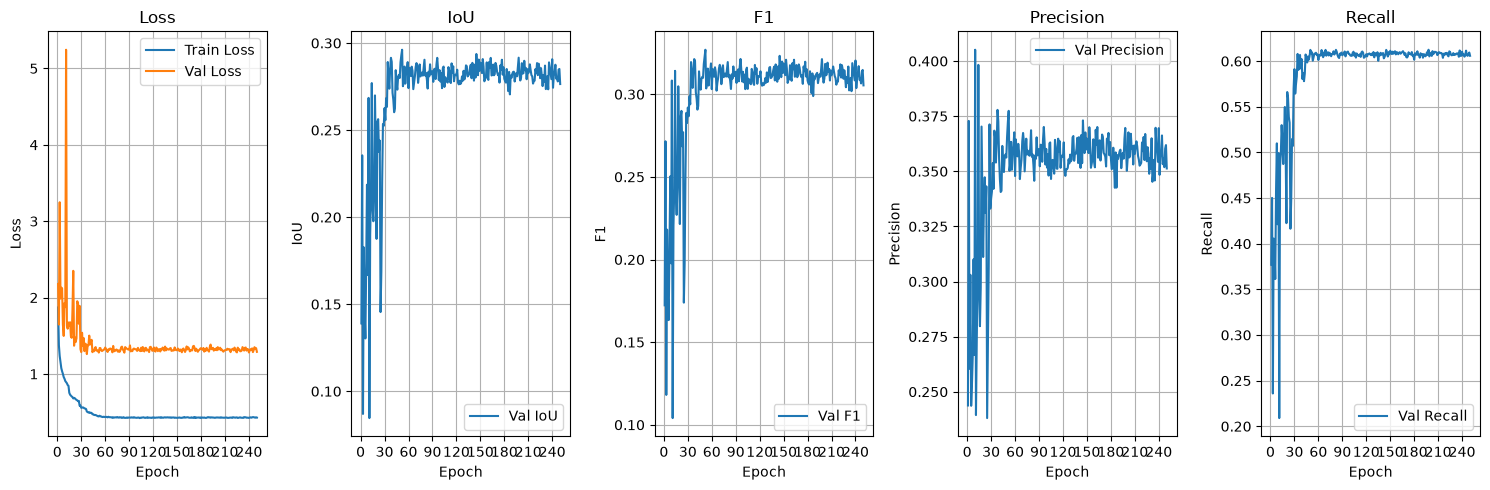

,epoch,train_loss,val_loss,val_iou,val_f1,val_precision,val_recall
0,1,1.870228,2.177769,0.138967,0.172302,0.243779,0.376941
1,2,1.374187,1.646580,0.235515,0.271559,0.372857,0.450119
2,3,1.234227,3.248210,0.086970,0.118088,0.260442,0.235964
3,4,1.149192,1.986922,0.182668,0.218083,0.303039,0.405653
4,5,1.075244,2.130154,0.146341,0.178087,0.243630,0.398647
...,...,...,...,...,...,...,...
245,246,0.433533,1.313366,0.280213,0.309385,0.355852,0.606493
246,247,0.429870,1.350243,0.277968,0.306560,0.351876,0.605765
247,248,0.426996,1.332744,0.284747,0.313792,0.360295,0.607430
248,249,0.432341,1.337744,0.285108,0.314726,0.361894,0.609408


In [21]:
import geoai

model_dir = project_dir / "models/unet_80band_monthly_weighted_250epochs"

geoai.plot_performance_metrics(
    history_path=str(model_dir / "training_history.pth"),
    figsize=(15, 5),
    verbose=True,
)

In [22]:
from pathlib import Path
import geoai
import rasterio
import numpy as np
import torch

experiment_name = "unet_80band_monthly_weighted_250epochs"  # Your experiment name

model_dir = project_dir / "models" / experiment_name
model_path = model_dir / "best_model.pth"

stage_images = (
    project_dir
    / "data/processed/geoai_training_input"
    / experiment_name
    / "images"
)

val_labels_dir = (
    project_dir / "data/processed/tiles_80band/val/labels"
)

predictions_dir = model_dir / "validation_predictions"
predictions_dir.mkdir(parents=True, exist_ok=True)

# Use ONLY filenames assigned to geographic validation areas
val_images = sorted(
    stage_images / p.name
    for p in val_labels_dir.glob("*.tif")
)

assert model_path.exists(), f"Model not found: {model_path}"
assert val_images, "No validation images found"
assert all(p.exists() for p in val_images), "Missing staged validation images"

device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

for i, image_path in enumerate(val_images, start=1):
    output_path = predictions_dir / image_path.name

    geoai.semantic_segmentation(
        input_path=str(image_path),
        output_path=str(output_path),
        model_path=str(model_path),
        architecture="unet",
        encoder_name="resnet18",
        num_channels=80,
        num_classes=30,
        window_size=128,
        overlap=0,
        batch_size=1,
        device=device,
        quiet=True,
    )

    if i % 25 == 0 or i == len(val_images):
        print(f"Predicted {i}/{len(val_images)} tiles")

print("\nValidation predictions saved to:", predictions_dir)

Predicted 25/392 tiles


KeyboardInterrupt: 

In [23]:
import numpy as np
import pandas as pd
import rasterio

n_classes = 30
confusion = np.zeros((n_classes, n_classes), dtype=np.int64)

for image_path in val_images:
    label_path = val_labels_dir / image_path.name
    prediction_path = predictions_dir / image_path.name

    with rasterio.open(label_path) as src:
        truth = src.read(1)
        truth_crs = src.crs
        truth_transform = src.transform

    with rasterio.open(prediction_path) as src:
        prediction = src.read(1).astype(np.int64)

        assert src.crs == truth_crs
        assert src.transform.almost_equals(truth_transform)

    assert prediction.shape == truth.shape
    assert np.all((prediction >= 0) & (prediction < n_classes)), (
        f"Unexpected prediction values: {image_path.name}"
    )

    # Ignore background, overlapping fields and field boundaries (255)
    valid = (truth >= 1) & (truth <= n_classes)

    actual = truth[valid].astype(np.int64) - 1
    predicted = prediction[valid]

    confusion += np.bincount(
        n_classes * actual + predicted,
        minlength=n_classes**2
    ).reshape(n_classes, n_classes)

intersection = np.diag(confusion)
actual_count = confusion.sum(axis=1)
predicted_count = confusion.sum(axis=0)
union = actual_count + predicted_count - intersection

iou = np.divide(
    intersection, union,
    out=np.zeros(n_classes, dtype=float),
    where=union > 0
)

precision = np.divide(
    intersection, predicted_count,
    out=np.zeros(n_classes, dtype=float),
    where=predicted_count > 0
)

recall = np.divide(
    intersection, actual_count,
    out=np.zeros(n_classes, dtype=float),
    where=actual_count > 0
)

f1 = np.divide(
    2 * precision * recall,
    precision + recall,
    out=np.zeros(n_classes, dtype=float),
    where=(precision + recall) > 0
)

present = actual_count > 0

pixel_accuracy = intersection.sum() / max(confusion.sum(), 1)
mean_iou = iou[present].mean()
mean_f1 = f1[present].mean()

print(f"Validation pixel accuracy: {pixel_accuracy:.2%}")
print(f"Validation mean IoU:       {mean_iou:.2%}")
print(f"Validation mean F1:        {mean_f1:.2%}")
print(f"Crop classes in validation: {present.sum()} / {n_classes}")

# Convert original crop IDs back to names
id_to_crop = {class_id: name for name, class_id in crop_mapping.items()}

class_results = pd.DataFrame({
    "crop_id": np.arange(1, n_classes + 1),
    "crop": [id_to_crop.get(i, f"Crop {i}") for i in range(1, n_classes + 1)],
    "true_pixels": actual_count,
    "predicted_pixels": predicted_count,
    "IoU": iou,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
})

display(
    class_results[class_results["true_pixels"] > 0]
    .sort_values("IoU", ascending=False)
)

Validation pixel accuracy: 81.65%
Validation mean IoU:       35.85%
Validation mean F1:        45.33%
Crop classes in validation: 30 / 30


,crop_id,crop,true_pixels,predicted_pixels,IoU,Precision,Recall,F1
22,23,sugar_beet,157251,149587,0.917857,0.981690,0.933845,0.957170
26,27,winter_rapeseed_rape,141557,150453,0.903213,0.921085,0.978970,0.949146
25,26,winter_common_soft_wheat,620129,638992,0.875724,0.919963,0.947946,0.933745
24,25,winter_barley,288020,261539,0.854857,0.968414,0.879376,0.921750
10,11,maize_corn_popcorn,635792,588741,0.844040,0.952004,0.881552,0.915425
16,17,potatoes,190677,186520,0.788011,0.891261,0.871830,0.881439
15,16,permanent_grassland,463429,518895,0.751760,0.812419,0.909654,0.858291
14,15,peas,35523,35015,0.638095,0.784721,0.773499,0.779069
1,2,asparagus,41970,38852,0.590890,0.772650,0.715249,0.742842
12,13,onions,32302,27535,0.557931,0.778246,0.663395,0.716246


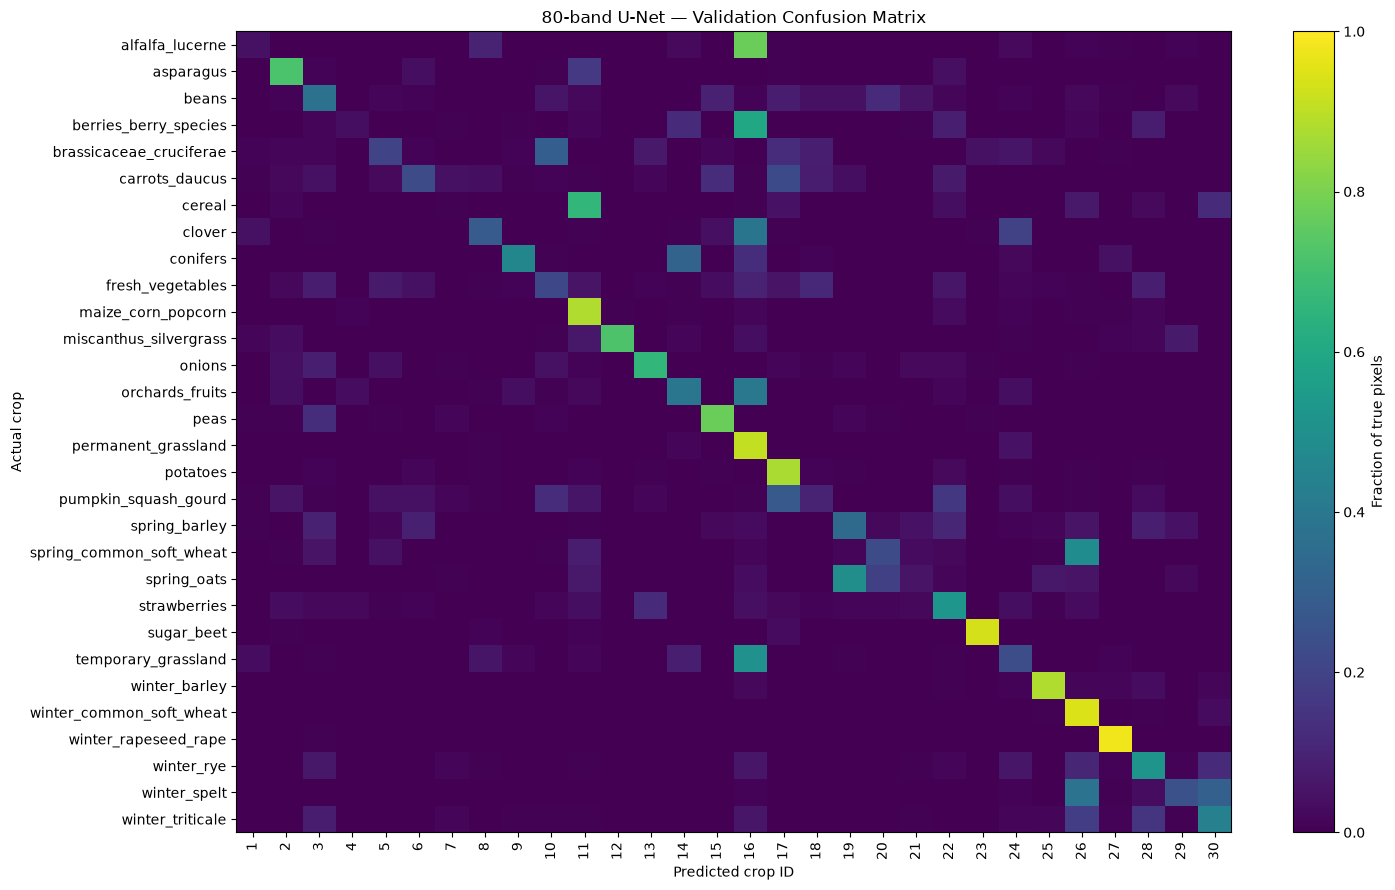

In [24]:
import matplotlib.pyplot as plt
import numpy as np

# Show only classes actually present in validation
present_ids = np.where(actual_count > 0)[0]

cm = confusion[present_ids, :].astype(float)
cm /= np.maximum(cm.sum(axis=1, keepdims=True), 1)

fig, ax = plt.subplots(figsize=(15, 9))

im = ax.imshow(
    cm,
    cmap="viridis",
    vmin=0,
    vmax=1,
    aspect="auto"
)

ax.set_yticks(range(len(present_ids)))
ax.set_yticklabels([
    id_to_crop.get(i + 1, f"Crop {i + 1}")
    for i in present_ids
])

ax.set_xticks(range(n_classes))
ax.set_xticklabels(
    [str(i) for i in range(1, n_classes + 1)],
    rotation=90
)

ax.set_xlabel("Predicted crop ID")
ax.set_ylabel("Actual crop")
ax.set_title("80-band U-Net — Validation Confusion Matrix")

plt.colorbar(im, ax=ax, label="Fraction of true pixels")
plt.tight_layout()
plt.show()

In [25]:
display(
    class_results[
        ["crop", "true_pixels", "predicted_pixels",
         "IoU", "Precision", "Recall", "F1"]
    ].sort_values("IoU", ascending=False)
)

,crop,true_pixels,predicted_pixels,IoU,Precision,Recall,F1
22,sugar_beet,157251,149587,0.917857,0.981690,0.933845,0.957170
26,winter_rapeseed_rape,141557,150453,0.903213,0.921085,0.978970,0.949146
25,winter_common_soft_wheat,620129,638992,0.875724,0.919963,0.947946,0.933745
24,winter_barley,288020,261539,0.854857,0.968414,0.879376,0.921750
10,maize_corn_popcorn,635792,588741,0.844040,0.952004,0.881552,0.915425
16,potatoes,190677,186520,0.788011,0.891261,0.871830,0.881439
15,permanent_grassland,463429,518895,0.751760,0.812419,0.909654,0.858291
14,peas,35523,35015,0.638095,0.784721,0.773499,0.779069
1,asparagus,41970,38852,0.590890,0.772650,0.715249,0.742842
12,onions,32302,27535,0.557931,0.778246,0.663395,0.716246


# New Model Rare crop aware sampling

What the modified training does
It uses your existing training masks to identify rare crop classes and then preferentially repeats training tiles containing those crops.
- Every original training tile remains in the dataset.
- Extra training appearances equal approximately 50% of the original training-tile count.
- Tiles containing rare crops are more likely to receive extra appearances.
- No tile appears more than four times per epoch.
- Your existing class-weighted cross-entropy loss remains enabled.
- Geographic validation and test splits remain unchanged.
For example, if you have 2,000 original training tiles, the model would see approximately 3,000 tile appearances per epoch, with the additional 1,000 biased toward rare crops

In [27]:
from pathlib import Path
from scripts.geoai_training_rare_crop import build_rare_crop_sampling

project_dir = Path(
    "/Users/henristaehelin/Desktop/UZH/SDS320/project"
)

tiles_dir = project_dir / "data/processed/tiles_80band"

repeats, summary = build_rare_crop_sampling(
    tiles_dir / "train/labels",
    num_classes=30,
    extra_fraction=0.50,
    sampling_strength=2.0,
    max_tile_repeats=4,
    seed=42,
)

print(summary)

{'original_tiles': 1715, 'extra_tiles': 858, 'effective_epoch_tiles': 2573, 'max_repeats': 4, 'present_classes': 30, 'rare_classes_1based': [12, 4, 9, 10, 18, 1, 7, 22], 'rare_class_weights': [4.27, 2.68, 2.34, 2.32, 1.81, 1.79, 1.65, 1.65]}


In [28]:
from pathlib import Path
import importlib
import scripts.geoai_training_rare_crop as training

importlib.reload(training)

project_dir = Path(
    "/Users/henristaehelin/Desktop/UZH/SDS320/project"
)

result = training.train_geoai_unet(
    project_dir=project_dir,
    experiment_name="unet_80band_rare_crop_earlystop",
    tiles_dir=project_dir / "data/processed/tiles_80band",
    num_channels=80,
    num_classes=30,

    rare_crop_sampling=True,
    extra_fraction=0.50,
    sampling_strength=2.0,
    max_tile_repeats=4,
    sampling_seed=42,

    use_class_weights=True,
    num_epochs=150,
    early_stopping_patience=25,
    batch_size=2,
    learning_rate=0.001,
    num_workers=0,
)

Geographic split: 1715 train tiles, 392 val tiles; 0 test tiles
Classes in training: 30/30
Class weight range: 0.200–3.682
Rare-crop sampling: {'original_tiles': 1715, 'extra_tiles': 858, 'effective_epoch_tiles': 2573, 'max_repeats': 4, 'present_classes': 30, 'rare_classes_1based': [12, 4, 9, 10, 18, 1, 7, 22], 'rare_class_weights': [4.27, 2.68, 2.34, 2.32, 1.81, 1.79, 1.65, 1.65]}
Fixed geographic split: 1715 unique train tiles (2573 appearances/epoch), 392 val tiles


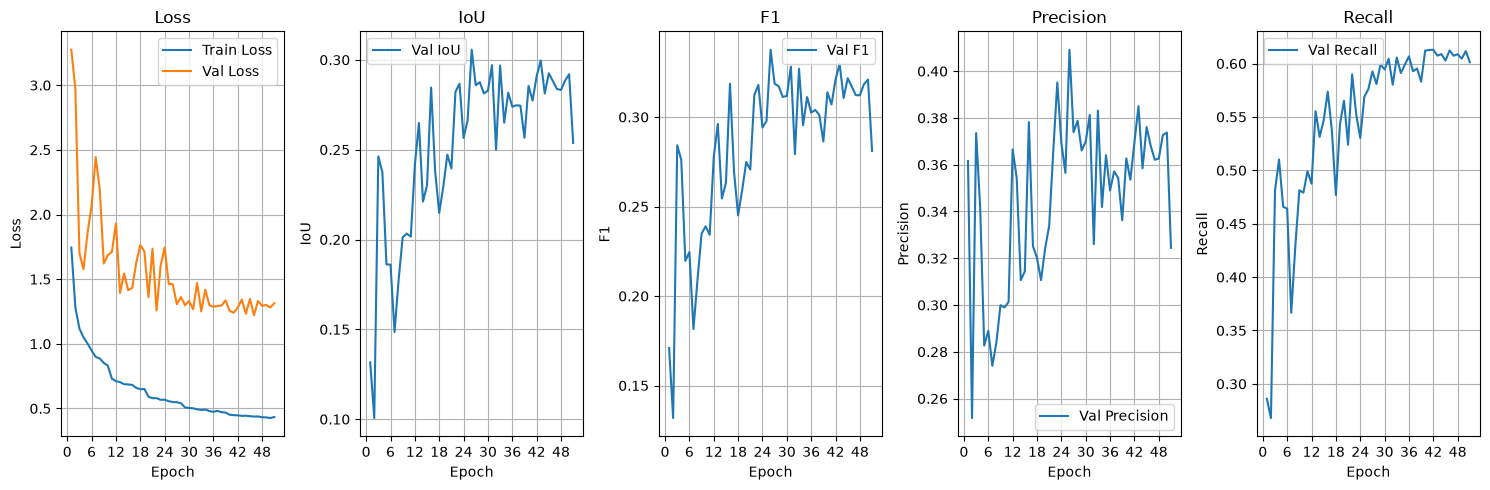

,epoch,train_loss,val_loss,val_iou,val_f1,val_precision,val_recall
0,1,1.744454,3.274156,0.131586,0.170968,0.361591,0.286012
1,2,1.279809,2.972458,0.100620,0.131811,0.251647,0.267961
2,3,1.117505,1.700742,0.246271,0.284220,0.373511,0.481101
3,4,1.049893,1.576481,0.237442,0.276076,0.341859,0.510201
4,5,1.001830,1.857344,0.186151,0.219622,0.282655,0.465926
5,6,0.947625,2.070376,0.186028,0.224570,0.288982,0.464098
6,7,0.899091,2.443970,0.148503,0.181561,0.274013,0.366560
7,8,0.886626,2.195170,0.177578,0.209212,0.284031,0.428248
8,9,0.851958,1.620960,0.201216,0.234835,0.299912,0.481273
9,10,0.830210,1.685630,0.203274,0.238959,0.298974,0.479066


In [29]:
import geoai

model_dir = project_dir / "models/unet_80band_rare_crop_earlystop"

geoai.plot_performance_metrics(
    history_path=str(model_dir / "training_history.pth"),
    figsize=(15, 5),
    verbose=True,
)

In [30]:
from pathlib import Path
import geoai
import rasterio
import numpy as np
import torch

experiment_name = "unet_80band_rare_crop_earlystop"  # Your experiment name

model_dir = project_dir / "models" / experiment_name
model_path = model_dir / "best_model.pth"

stage_images = (
    project_dir
    / "data/processed/geoai_training_input"
    / experiment_name
    / "images"
)

val_labels_dir = (
    project_dir / "data/processed/tiles_80band/val/labels"
)

predictions_dir = model_dir / "validation_predictions"
predictions_dir.mkdir(parents=True, exist_ok=True)

# Use ONLY filenames assigned to geographic validation areas
val_images = sorted(
    stage_images / p.name
    for p in val_labels_dir.glob("*.tif")
)

assert model_path.exists(), f"Model not found: {model_path}"
assert val_images, "No validation images found"
assert all(p.exists() for p in val_images), "Missing staged validation images"

device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

for i, image_path in enumerate(val_images, start=1):
    output_path = predictions_dir / image_path.name

    geoai.semantic_segmentation(
        input_path=str(image_path),
        output_path=str(output_path),
        model_path=str(model_path),
        architecture="unet",
        encoder_name="resnet18",
        num_channels=80,
        num_classes=30,
        window_size=128,
        overlap=0,
        batch_size=1,
        device=device,
        quiet=True,
    )

    if i % 25 == 0 or i == len(val_images):
        print(f"Predicted {i}/{len(val_images)} tiles")

print("\nValidation predictions saved to:", predictions_dir)

Predicted 25/392 tiles
Predicted 50/392 tiles
Predicted 75/392 tiles
Predicted 100/392 tiles
Predicted 125/392 tiles
Predicted 150/392 tiles
Predicted 175/392 tiles
Predicted 200/392 tiles
Predicted 225/392 tiles
Predicted 250/392 tiles
Predicted 275/392 tiles
Predicted 300/392 tiles
Predicted 325/392 tiles
Predicted 350/392 tiles
Predicted 375/392 tiles
Predicted 392/392 tiles

Validation predictions saved to: /Users/henristaehelin/Desktop/UZH/SDS320/project/models/unet_80band_rare_crop_earlystop/validation_predictions


In [31]:
import numpy as np
import pandas as pd
import rasterio

n_classes = 30
confusion = np.zeros((n_classes, n_classes), dtype=np.int64)

for image_path in val_images:
    label_path = val_labels_dir / image_path.name
    prediction_path = predictions_dir / image_path.name

    with rasterio.open(label_path) as src:
        truth = src.read(1)
        truth_crs = src.crs
        truth_transform = src.transform

    with rasterio.open(prediction_path) as src:
        prediction = src.read(1).astype(np.int64)

        assert src.crs == truth_crs
        assert src.transform.almost_equals(truth_transform)

    assert prediction.shape == truth.shape
    assert np.all((prediction >= 0) & (prediction < n_classes)), (
        f"Unexpected prediction values: {image_path.name}"
    )

    # Ignore background, overlapping fields and field boundaries (255)
    valid = (truth >= 1) & (truth <= n_classes)

    actual = truth[valid].astype(np.int64) - 1
    predicted = prediction[valid]

    confusion += np.bincount(
        n_classes * actual + predicted,
        minlength=n_classes**2
    ).reshape(n_classes, n_classes)

intersection = np.diag(confusion)
actual_count = confusion.sum(axis=1)
predicted_count = confusion.sum(axis=0)
union = actual_count + predicted_count - intersection

iou = np.divide(
    intersection, union,
    out=np.zeros(n_classes, dtype=float),
    where=union > 0
)

precision = np.divide(
    intersection, predicted_count,
    out=np.zeros(n_classes, dtype=float),
    where=predicted_count > 0
)

recall = np.divide(
    intersection, actual_count,
    out=np.zeros(n_classes, dtype=float),
    where=actual_count > 0
)

f1 = np.divide(
    2 * precision * recall,
    precision + recall,
    out=np.zeros(n_classes, dtype=float),
    where=(precision + recall) > 0
)

present = actual_count > 0

pixel_accuracy = intersection.sum() / max(confusion.sum(), 1)
mean_iou = iou[present].mean()
mean_f1 = f1[present].mean()

print(f"Validation pixel accuracy: {pixel_accuracy:.2%}")
print(f"Validation mean IoU:       {mean_iou:.2%}")
print(f"Validation mean F1:        {mean_f1:.2%}")
print(f"Crop classes in validation: {present.sum()} / {n_classes}")

# Convert original crop IDs back to names
id_to_crop = {class_id: name for name, class_id in crop_mapping.items()}

class_results = pd.DataFrame({
    "crop_id": np.arange(1, n_classes + 1),
    "crop": [id_to_crop.get(i, f"Crop {i}") for i in range(1, n_classes + 1)],
    "true_pixels": actual_count,
    "predicted_pixels": predicted_count,
    "IoU": iou,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
})

display(
    class_results[class_results["true_pixels"] > 0]
    .sort_values("IoU", ascending=False)
)

Validation pixel accuracy: 80.28%
Validation mean IoU:       33.98%
Validation mean F1:        42.93%
Crop classes in validation: 30 / 30


,crop_id,crop,true_pixels,predicted_pixels,IoU,Precision,Recall,F1
26,27,winter_rapeseed_rape,141557,139740,0.934789,0.972578,0.960094,0.966295
22,23,sugar_beet,157251,147458,0.915963,0.987888,0.926366,0.956138
25,26,winter_common_soft_wheat,620129,682259,0.851471,0.877898,0.965854,0.919778
24,25,winter_barley,288020,264417,0.821031,0.941967,0.864773,0.901721
10,11,maize_corn_popcorn,635792,595496,0.812095,0.926631,0.867902,0.896305
16,17,potatoes,190677,192708,0.781645,0.872818,0.882115,0.877442
15,16,permanent_grassland,463429,653837,0.679604,0.691411,0.975489,0.809243
14,15,peas,35523,28043,0.601441,0.851300,0.672043,0.751125
12,13,onions,32302,25980,0.588671,0.831255,0.668565,0.741086
1,2,asparagus,41970,33947,0.529814,0.774501,0.626447,0.692651


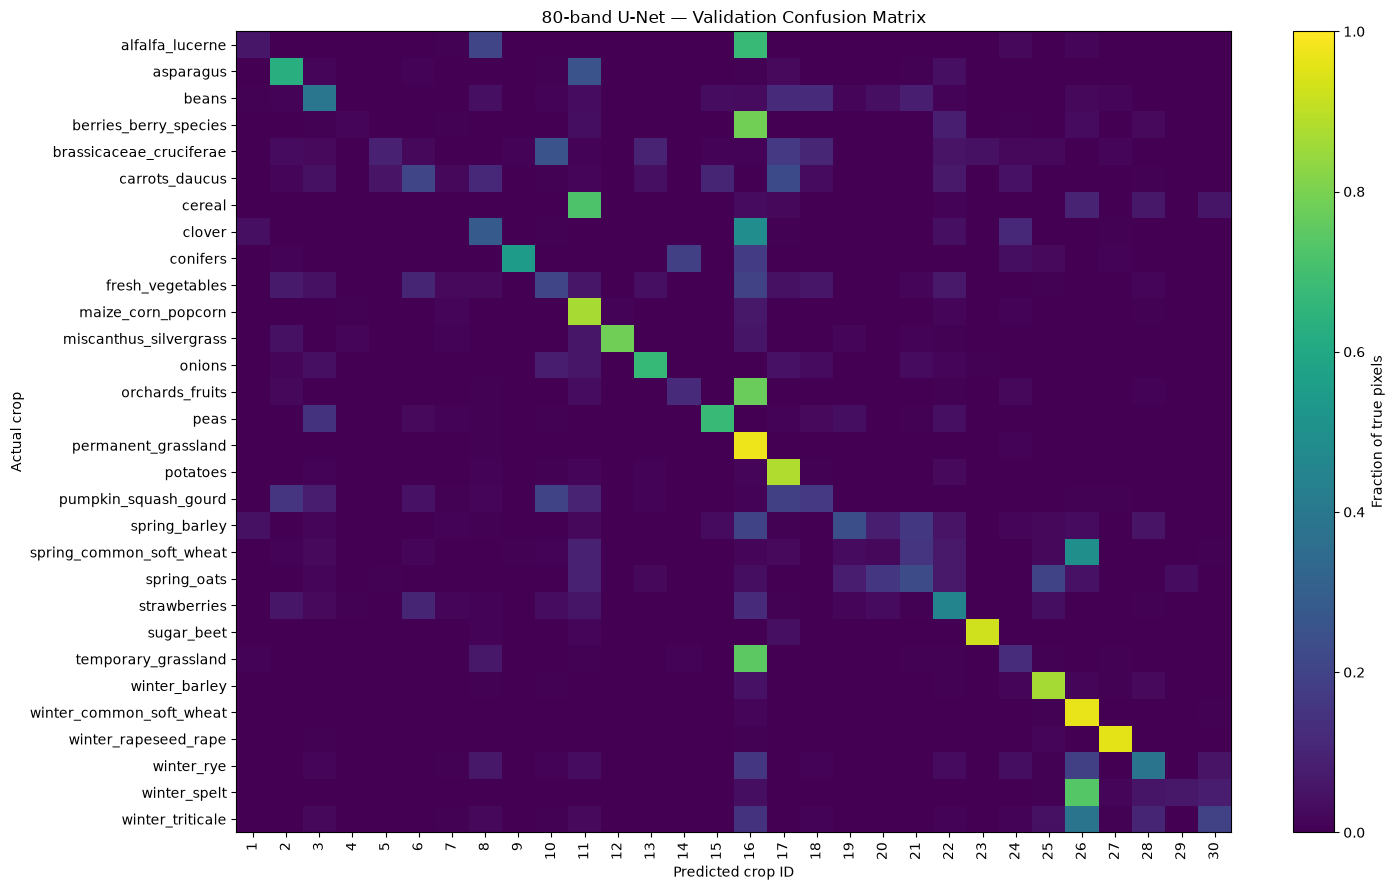

In [32]:
import matplotlib.pyplot as plt
import numpy as np

# Show only classes actually present in validation
present_ids = np.where(actual_count > 0)[0]

cm = confusion[present_ids, :].astype(float)
cm /= np.maximum(cm.sum(axis=1, keepdims=True), 1)

fig, ax = plt.subplots(figsize=(15, 9))

im = ax.imshow(
    cm,
    cmap="viridis",
    vmin=0,
    vmax=1,
    aspect="auto"
)

ax.set_yticks(range(len(present_ids)))
ax.set_yticklabels([
    id_to_crop.get(i + 1, f"Crop {i + 1}")
    for i in present_ids
])

ax.set_xticks(range(n_classes))
ax.set_xticklabels(
    [str(i) for i in range(1, n_classes + 1)],
    rotation=90
)

ax.set_xlabel("Predicted crop ID")
ax.set_ylabel("Actual crop")
ax.set_title("80-band U-Net — Validation Confusion Matrix")

plt.colorbar(im, ax=ax, label="Fraction of true pixels")
plt.tight_layout()
plt.show()

# Evaluating per crop field, instead of per pixel.
This is less rigorous but still reaches our overall goal of identifying crop types in fields. 

In [33]:
from pathlib import Path

project_dir = Path(
    "/Users/henristaehelin/Desktop/UZH/SDS320/project"
)

for p in sorted((project_dir / "models").glob("*/best_model.pth")):
    print(p)

/Users/henristaehelin/Desktop/UZH/SDS320/project/models/unet_80band_monthly_weighted/best_model.pth
/Users/henristaehelin/Desktop/UZH/SDS320/project/models/unet_80band_monthly_weighted_250epochs/best_model.pth
/Users/henristaehelin/Desktop/UZH/SDS320/project/models/unet_80band_monthly_weighted_50epochs/best_model.pth
/Users/henristaehelin/Desktop/UZH/SDS320/project/models/unet_80band_rare_crop_earlystop/best_model.pth
/Users/henristaehelin/Desktop/UZH/SDS320/project/models/unet_geoai/best_model.pth
/Users/henristaehelin/Desktop/UZH/SDS320/project/models/unet_geoai_imagenet/best_model.pth
/Users/henristaehelin/Desktop/UZH/SDS320/project/models/unet_geoai_imagenet_cropweighted/best_model.pth
/Users/henristaehelin/Desktop/UZH/SDS320/project/models/unet_geoai_imagenet_cropweighted_10band/best_model.pth
/Users/henristaehelin/Desktop/UZH/SDS320/project/models/unet_geoai_imagenet_cropweighted_expanded/best_model.pth


In [34]:
import importlib
import scripts.field_level_comparison as field_eval

importlib.reload(field_eval)

model_paths = {
    "baseline": project_dir / "models/unet_80band_monthly_weighted_250epochs/best_model.pth",
    "rare_crop": project_dir / "models/unet_80band_rare_crop_earlystop/best_model.pth",
}

field_predictions, field_metrics, field_summary = (
    field_eval.compare_models_by_field(
        project_dir=project_dir,
        crop_fields=reduced_crops,
        crop_mapping=crop_mapping,
        model_paths=model_paths,
        tiles_dir=project_dir / "data/processed/tiles_80band",
        min_field_pixels=10,
    )
)

display(field_summary)

Validation: 392 tiles across 8 geographic areas
baseline: 392 tiles to predict; 0 cached
  baseline: 100/392 generated
  baseline: 200/392 generated
  baseline: 300/392 generated
  baseline: 392/392 generated
rare_crop: 392 tiles to predict; 0 cached
  rare_crop: 100/392 generated
  rare_crop: 200/392 generated
  rare_crop: 300/392 generated
  rare_crop: 392/392 generated
[1/8] area 1: 710 mapped fields
[2/8] area 7: 778 mapped fields
[3/8] area 12: 961 mapped fields
[4/8] area 13: 1076 mapped fields
[5/8] area 15: 711 mapped fields
[6/8] area 20: 526 mapped fields
[7/8] area 23: 917 mapped fields
[8/8] area 36: 482 mapped fields

FIELD-LEVEL RESULTS (each physical field counts once)
    model  evaluated_fields  field_accuracy  macro_field_IoU  macro_field_F1  mean_field_vote_share
 baseline              5822           0.801            0.379           0.478                  0.896
rare_crop              5822           0.788            0.339           0.428                  0.913

PER-CR

,model,evaluated_fields,field_accuracy,macro_field_IoU,macro_field_F1,mean_field_vote_share
0,baseline,5822,0.800756,0.379180,0.478395,0.896175
1,rare_crop,5822,0.788217,0.339428,0.427968,0.912977


In [35]:
comparison = field_metrics.pivot(
    index=["crop_id", "crop"],
    columns="model",
    values="field_recall"
)

comparison["change"] = (
    comparison["rare_crop"] - comparison["baseline"]
)

display(comparison.sort_values("change", ascending=False))

,model,baseline,rare_crop,change
crop_id,crop,,,
18,pumpkin_squash_gourd,0.080000,0.240000,0.160000
21,spring_oats,0.000000,0.111111,0.111111
3,beans,0.369565,0.456522,0.086957
1,alfalfa_lucerne,0.000000,0.062500,0.062500
16,permanent_grassland,0.935854,0.984470,0.048616
26,winter_common_soft_wheat,0.931643,0.963616,0.031974
9,conifers,0.357143,0.357143,0.000000
7,cereal,0.000000,0.000000,0.000000
17,potatoes,0.836820,0.832636,-0.004184


In [36]:
display(field_summary)

,model,evaluated_fields,field_accuracy,macro_field_IoU,macro_field_F1,mean_field_vote_share
0,baseline,5822,0.800756,0.379180,0.478395,0.896175
1,rare_crop,5822,0.788217,0.339428,0.427968,0.912977


Most pixels in the fields are already the correct identification (89 or 91%) field level evaluation is somewhat helpful, but it explains why the difference in pixel and field accuracy is so similar. The fields that are wrong contain many pixels that are wrong. 